# AF 4: Simulación del robot manipulador planar de 2 gdl

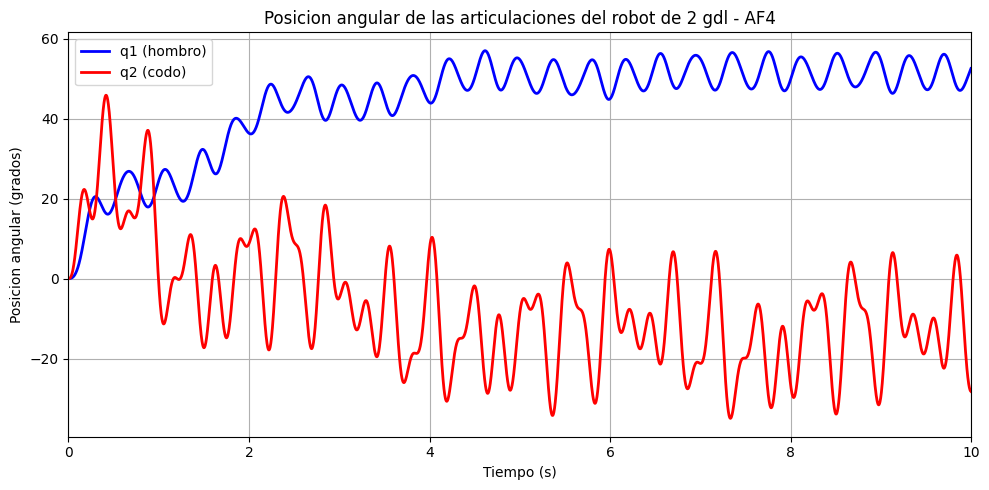

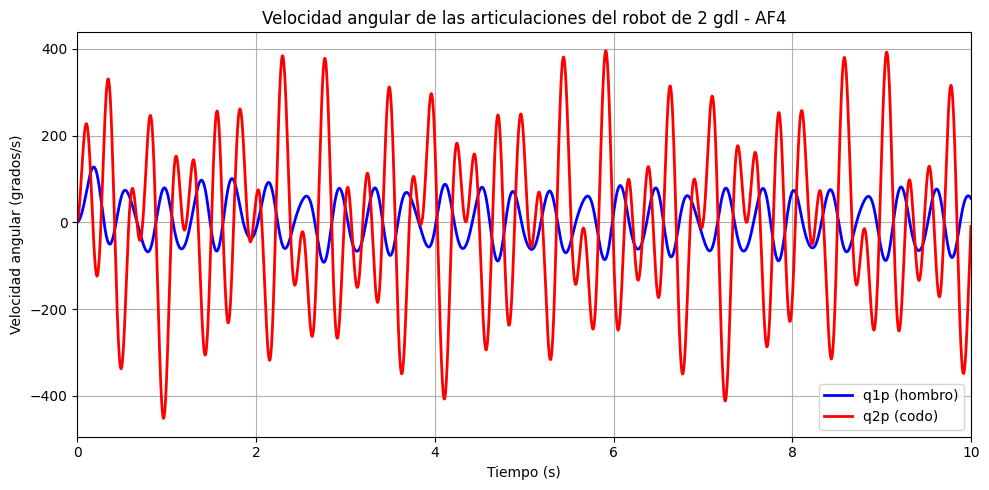

       RESULTADOS DE LA AF4

CONDICIONES INICIALES:
X1 = q1(0)  = 0.0
X2 = q2(0)  = 0.0
X3 = q1p(0) = 0.0
X4 = q2p(0) = 0.0

RESULTADOS FINALES:
Tiempo de simulacion: 10.0 segundos
Posicion final q1 (hombro): 52.56155033763265 grados
Posicion final q2 (codo):   -28.233447608712826 grados
Velocidad final q1p: 55.274503082260885 grados/s
Velocidad final q2p: -9.445197505800529 grados/s


In [2]:
# ============================================================
# INTEGRANTES DEL EQUIPO
# ============================================================
# Juan Carlos Castillo Guerra       2144789
# Perla Ximena Álvarez Silerio      2142704
# Arturo Rosales Ponce              2142669
# Samantha Nohemi Moreno Treviño    2154902

# ============================================================
# AF 4 - PROYECTO FINAL
# ROBOT MANIPULADOR PLANAR DE 2 GRADOS DE LIBERTAD
# MODELO OBTENIDO MEDIANTE EULER-LAGRANGE
#
# Modelo:  M(q)q'' + C(q,q')q' + g(q) + f(q') = tau
# Despeje: q'' = M^-1 [ tau - C q' - g - f ]
# ============================================================

import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. MATRICES DEL MODELO DINAMICO
# ------------------------------------------------------------

# Matriz de inercia M(q)
def M(q):
    q2 = q[1]
    return np.array([[3.117 + 0.2*np.cos(q2), 0.108 + 0.1*np.cos(q2)],
                     [0.108 + 0.1*np.cos(q2), 0.108]])

# Matriz de Coriolis y centripeta C(q, q')
def C(q, qp):
    q2 = q[1]
    return np.array([[-0.2*np.sin(q2)*qp[1], -0.1*np.sin(q2)*qp[1]],
                     [ 0.1*np.sin(q2)*qp[0],  0.0]])

# Vector de gravedad g(q)
def g(q):
    q1, q2 = q
    return np.array([39.3*np.sin(q1) + 1.95*np.sin(q1 + q2),
                     1.95*np.sin(q1 + q2)])

# Vector de friccion f(q'): viscosa + Coulomb.
def f_fric(qp):
    k = 100000
    return np.array([1.86*qp[0] + 1.93*np.tanh(k*qp[0]),
                     0.16*qp[1] + 0.30*np.tanh(k*qp[1])])

# ------------------------------------------------------------
# 2. TORQUE DE LOS MOTORES
#    tau1 = (1-e^(-0.8t))*32  + 56 sen(16t+0.1) + 12 sen(20t+0.15)
#    tau2 = (1-e^(-1.8t))*1.2 +  8 sen(26t+0.08) +  2 sen(12t+0.34)
# ------------------------------------------------------------

def tau(t):
    t1 = (1 - np.exp(-0.8*t))*32  + 56*np.sin(16*t + 0.1) + 12*np.sin(20*t + 0.15)
    t2 = (1 - np.exp(-1.8*t))*1.2 +  8*np.sin(26*t + 0.08) +  2*np.sin(12*t + 0.34)
    return np.array([t1, t2])

# ------------------------------------------------------------
# 3. MODELO DINAMICO EN VARIABLES DE ESTADO
#    x = [x1, x2, x3, x4] = [q1, q2, q1p, q2p]
# ------------------------------------------------------------

def f(t, x):

    # Variables de estado
    q  = x[0:2]    # x1, x2: posiciones angulares (hombro, codo)
    qp = x[2:4]    # x3, x4: velocidades angulares (hombro, codo)

    # Aceleraciones: q'' = M^-1 [ tau - C q' - g - f ]
    qpp = np.linalg.solve(M(q), tau(t) - C(q, qp) @ qp - g(q) - f_fric(qp))

    # Espacio de estados: [x1p, x2p, x3p, x4p] = [x3, x4, qpp1, qpp2]
    return [qp[0], qp[1], qpp[0], qpp[1]]

# ------------------------------------------------------------
# 4. CONDICIONES INICIALES
# ------------------------------------------------------------

ti = 0.0
tf = 10.0
h  = 0.0025

X1 = 0.0    # q1(0)  Posicion del hombro
X2 = 0.0    # q2(0)  Posicion del codo
X3 = 0.0    # q1p(0) Velocidad del hombro
X4 = 0.0    # q2p(0) Velocidad del codo

x0 = [X1, X2, X3, X4]

# Tiempo de simulacion
ts = np.arange(ti, tf, h)

# ------------------------------------------------------------
# 5. SIMULACION NUMERICA
# ------------------------------------------------------------

sol = solve_ivp(f, [ti, tf], x0, t_eval=ts,
                method='LSODA', rtol=1e-6, atol=1e-8)

# Extraer resultados
t = sol.t
q1, q2, q1p, q2p = sol.y

# Conversion de radianes a grados
q1_grados  = np.rad2deg(q1)
q2_grados  = np.rad2deg(q2)
q1p_grados = np.rad2deg(q1p)
q2p_grados = np.rad2deg(q2p)

# ------------------------------------------------------------
# 6. GRAFICA DE POSICION ANGULAR
# ------------------------------------------------------------

plt.figure(figsize=(10,5))

plt.plot(t, q1_grados, 'b', linewidth=2, label='q1 (hombro)')
plt.plot(t, q2_grados, 'r', linewidth=2, label='q2 (codo)')

plt.title('Posicion angular de las articulaciones del robot de 2 gdl - AF4')
plt.xlabel('Tiempo (s)')
plt.ylabel('Posicion angular (grados)')
plt.grid(True)
plt.legend()
plt.xlim(0,10)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. GRAFICA DE VELOCIDAD ANGULAR
# ------------------------------------------------------------

plt.figure(figsize=(10,5))

plt.plot(t, q1p_grados, 'b', linewidth=2, label='q1p (hombro)')
plt.plot(t, q2p_grados, 'r', linewidth=2, label='q2p (codo)')

plt.title('Velocidad angular de las articulaciones del robot de 2 gdl - AF4')
plt.xlabel('Tiempo (s)')
plt.ylabel('Velocidad angular (grados/s)')
plt.grid(True)
plt.legend()
plt.xlim(0,10)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. RESULTADOS DE LA SIMULACION
# ------------------------------------------------------------

print("======================================")
print("       RESULTADOS DE LA AF4")
print("======================================")

print("\nCONDICIONES INICIALES:")
print("X1 = q1(0)  =", X1)
print("X2 = q2(0)  =", X2)
print("X3 = q1p(0) =", X3)
print("X4 = q2p(0) =", X4)

print("\nRESULTADOS FINALES:")
print("Tiempo de simulacion:", tf, "segundos")
print("Posicion final q1 (hombro):", q1_grados[-1], "grados")
print("Posicion final q2 (codo):  ", q2_grados[-1], "grados")
print("Velocidad final q1p:", q1p_grados[-1], "grados/s")
print("Velocidad final q2p:", q2p_grados[-1], "grados/s")

print("======================================")
